# 项目一 · 心脏病发病预测 —— 数据分析与建模 Notebook

> 对应《数据分析实务实训》任务书 · 数据：`heart.csv`（1303 条记录，12 字段）

**本 Notebook 的定位（请务必先读）**

- 本文件**只负责数据操作**：数据探查清洗、EDA 可视化、多模型对比、算法调优、评估绘图。
- 任务书中「为什么做 / 如何做 / 结果 / 核心结论 / 核心建议」等文字**要求本人理解后填写**。本 Notebook 已在各占位处填入基于真实运行结果的**参考文字与截图位置**，请按本人表述习惯核对、调整后再提交。
- 每张图均保存到 `img/` 目录，便于直接"贴图"到报告；图的代码里写了读图要点，解读文字请自己组织。
- 代码中的中文注释用于解释**每一步在做什么、为什么这么做**，方便你理解后独立复述。

**目录**
1. 数据探查与清洗
2. EDA 可视化
3. 多模型预测对比与分析
4. 算法优化
5. 结论与报告
6. 附录：AI 辅助使用说明

## 0. 环境准备与全局设置

导入后续需要的库，并统一做三件事：
1. 设置随机种子 → 保证划分数据集、模型训练的**结果可复现**（同一份代码每次跑结果一致）。
2. 设置中文字体 → 让 matplotlib 图表里的中文标题、坐标轴标签正常显示，不出现方块。
3. 创建图片目录 → 统一存放可视化结果，方便贴图。

In [1]:
# ---------- 导库 ----------
import numpy as np                      # 数值计算、数组操作
import pandas as pd                     # 表格数据处理（核心工具）
import matplotlib.pyplot as plt         # 绘图（底层）
import seaborn as sns                   # 绘图（统计图形更高级、更好看）
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')       # 忽略收敛等无害警告，让输出更干净

# ---------- 可复现 & 中文显示 ----------
RANDOM_SEED = 42                        # 固定随机种子，保证结果可重复
np.random.seed(RANDOM_SEED)

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']  # Windows 中文字体
plt.rcParams['axes.unicode_minus'] = False                       # 负号正常显示（Oldpeak 有负值）
sns.set_theme(style='whitegrid', palette='Set2')                 # 统一图表风格

import os
FIG_DIR = 'img'                     # 图片输出目录
os.makedirs(FIG_DIR, exist_ok=True)
print('环境准备完成，图片将保存到:', os.path.abspath(FIG_DIR))

环境准备完成，图片将保存到: C:\Users\szpt\Desktop\心脏病发病预测-实训\figures


---
## 1. 数据探查与清洗

> 对应任务书第 1 部分

**为什么做**：对脏数据进行处理，方便后续分析，不让脏数据干扰分析结果

**如何做**：重复的删掉，缺失值用众数、中位数、平均数等填充，错误的数据去掉

下面用代码完成实际的数据操作。

### 1.1 读取数据与整体概览

先加载数据，看规模、字段类型、前几行，对数据建立整体印象。

In [2]:
df = pd.read_csv('data/heart.csv')           # 读取心脏病数据

print('数据规模：', df.shape, '（行数 × 列数）')
print('\n字段与数据类型：')
print(df.dtypes)
print('\n前 5 行：')
display(df.head())
print('\n数值字段统计描述：')
display(df.describe().round(2))

数据规模： (1303, 12) （行数 × 列数）

字段与数据类型：
Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

前 5 行：


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



数值字段统计描述：


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,1303.00,1303.00,1303.00,1303.00,1303.00,1303.00,1303.00
mean,53.12,132.77,188.07,0.24,134.96,0.84,0.57
std,9.49,18.85,116.41,0.43,25.68,1.05,0.50
min,28.00,0.00,0.00,0.00,60.00,-2.60,0.00
25%,47.00,120.00,147.00,0.00,118.00,0.00,0.00
50%,54.00,130.00,219.00,0.00,135.00,0.50,1.00
75%,60.00,140.00,264.00,0.00,154.00,1.50,1.00
max,77.00,200.00,603.00,1.00,202.00,6.20,1.00


### 1.2 缺失值检查

`isnull()` 检查是否有空值；注意任务书的数据字典提示：**RestingBP 与 Cholesterol 存在 0 值异常**——
"0"在生理上不可能是静息血压/胆固醇，它们其实是"缺失值被写成了 0"，要单独处理（见 1.4）。

In [3]:
missing = df.isnull().sum()
print('各字段缺失值数量：')
print(missing[missing > 0] if missing.sum() > 0 else '无空值（NaN）')

# 额外检查：生理上不可能的 0 值（数据字典明确点名的异常）
print('\n=== 生理不可能的 0 值检查 ===')
print('RestingBP == 0 的行数：', (df['RestingBP'] == 0).sum())
print('Cholesterol == 0 的行数：', (df['Cholesterol'] == 0).sum())
print('两列同时为 0 的行数：', ((df['RestingBP'] == 0) & (df['Cholesterol'] == 0)).sum())

各字段缺失值数量：
无空值（NaN）

=== 生理不可能的 0 值检查 ===
RestingBP == 0 的行数： 2
Cholesterol == 0 的行数： 304
两列同时为 0 的行数： 2


### 1.3 重复值检查（关键）

`duplicated()` 找出**完全重复**的行。重复样本如果同时出现在训练集和测试集，会造成"数据泄漏"，
让模型评估虚高。这里先如实统计，再在 1.5 决定如何处理。

In [4]:
dup_count = df.duplicated().sum()
print('完全重复的行数：', dup_count)
print('去重后剩余行数：', len(df) - dup_count)

if dup_count > 0:
    print('\n重复行示例（前 5 条重复记录）：')
    display(df[df.duplicated(keep=False)].head(10))

完全重复的行数： 386
去重后剩余行数： 917

重复行示例（前 5 条重复记录）：


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
37,41,F,ATA,110,250,0,ST,142,N,0.0,Up,0
38,48,F,ATA,120,177,1,ST,148,N,0.0,Up,0
39,48,F,ASY,150,227,0,Normal,130,Y,1.0,Flat,0
40,54,F,ATA,150,230,0,Normal,130,N,0.0,Up,0
41,54,F,NAP,130,294,0,ST,100,Y,0.0,Flat,1
42,35,M,ATA,150,264,0,Normal,168,N,0.0,Up,0
43,52,M,NAP,140,259,0,ST,170,N,0.0,Up,0
44,43,M,ASY,120,175,0,Normal,120,Y,1.0,Flat,1
45,59,M,NAP,130,318,0,Normal,120,Y,1.0,Flat,0
46,37,M,ASY,120,223,0,Normal,168,N,0.0,Up,0


### 1.4 异常值与类别取值检查

- **Cholesterol / RestingBP 的 0 值** → 视为缺失，稍后用中位数填充。
- **Oldpeak < 0** → 表示 ST 段*抬高*（相对静息），是有临床意义的合法值，**不要当成错误删除**。
- 类别字段取值应与数据字典一致，确认没有拼写错误或意外取值。

In [5]:
print('=== Oldpeak 负值（合法，代表 ST 段抬高，需保留）===')
print('Oldpeak < 0 的行数：', (df['Oldpeak'] < 0).sum())
display(df[df['Oldpeak'] < 0].head())

print('\n=== 各字段取值分布（类别字段核对）===')
for col in ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease']:
    print(f'--- {col} ---')
    print(df[col].value_counts().to_string())
    print()

=== Oldpeak 负值（合法，代表 ST 段抬高，需保留）===
Oldpeak < 0 的行数： 21


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
320,63,M,ASY,100,0,1,Normal,109,N,-0.9,Flat,1
323,46,M,ASY,100,0,1,ST,133,N,-2.6,Flat,1
324,42,M,ASY,105,0,1,Normal,128,Y,-1.5,Down,1
325,45,M,NAP,110,0,0,Normal,138,N,-0.1,Up,0
330,56,M,ASY,115,0,1,ST,82,N,-1.0,Up,1



=== 各字段取值分布（类别字段核对）===
--- Sex ---
M    1049
F     254

--- ChestPainType ---
ASY    718
NAP    271
ATA    253
TA      61

--- FastingBS ---
0    992
1    311

--- RestingECG ---
Normal    814
ST        285
LVH       204

--- ExerciseAngina ---
N    760
Y    543

--- ST_Slope ---
Flat    671
Up      549
Down     83

--- HeartDisease ---
1    739
0    564



### 1.5 执行清洗

清洗策略（逐步执行，每步都有注释）：

1. **删除完全重复行**：避免训练/测试集出现同一条样本导致评估虚高。
2. **0 → NaN**：把 RestingBP、Cholesterol 中生理不可能的 0 替换为缺失标记 NaN。
3. **中位数填充**：对这两列用中位数填充（比均值更稳健，不受极端值影响）。
   - 说明：更严格的做法是"只用训练集的中位数"来填充（放进 Pipeline），这里在探查清洗阶段先对整体填充便于 EDA；建模部分会用 Pipeline 做标准化防止泄漏。
4. **保留 Oldpeak 负值**：医学上合法。

In [6]:
df_clean = df.copy()
n_raw = len(df_clean)

# (1) 删除完全重复行
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# (2) 生理不可能的 0 值 -> NaN
df_clean['RestingBP'] = df_clean['RestingBP'].replace(0, np.nan)
df_clean['Cholesterol'] = df_clean['Cholesterol'].replace(0, np.nan)

# (3) 中位数填充（记录填充前后的中位数，便于说明）
for col in ['RestingBP', 'Cholesterol']:
    med = df_clean[col].median()
    n_fill = df_clean[col].isna().sum()
    df_clean[col] = df_clean[col].fillna(med)
    print(f'{col}: 填充 {n_fill} 个缺失值，使用中位数 = {med:.1f}')

df_clean = df_clean.reset_index(drop=True)
print(f'\n原始数据 {n_raw} 行 -> 清洗后 {len(df_clean)} 行')

RestingBP: 填充 1 个缺失值，使用中位数 = 130.0
Cholesterol: 填充 172 个缺失值，使用中位数 = 237.0

原始数据 1303 行 -> 清洗后 917 行


### 1.6 清洗后复核

再次检查缺失/重复/异常是否处理干净，并看目标变量分布（是否类别不平衡）。

In [7]:
print('清洗后空值总数：', df_clean.isnull().sum().sum())
print('清洗后重复行数：', df_clean.duplicated().sum())
print('RestingBP == 0：', (df_clean['RestingBP'] == 0).sum(),
      '| Cholesterol == 0：', (df_clean['Cholesterol'] == 0).sum())

print('\n目标变量 HeartDisease 分布：')
print(df_clean['HeartDisease'].value_counts().to_string())
print('患病比例：%.2f%%' % (df_clean['HeartDisease'].mean() * 100))
display(df_clean.head())

清洗后空值总数： 0
清洗后重复行数： 0
RestingBP == 0： 0 | Cholesterol == 0： 0

目标变量 HeartDisease 分布：
1    508
0    409
患病比例：55.40%


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0


**结果**：

![目标变量分布](img/01_目标分布.png)

原始数据共 1303 行 12 列。检查发现 386 条完全重复记录，去重后剩余 917 行，避免同一条样本同时出现在训练集和测试集中造成评估虚高。RestingBP 与 Cholesterol 中生理不可能的 0 值分别有 2 行和 304 行，按缺失值处理后用中位数填充（RestingBP=130，Cholesterol=237）；Oldpeak 小于 0 的 21 行属于医学上合法的 ST 段抬高，予以保留。清洗后无空值、无重复，其中患病 508 例、未患病 409 例，患病率 55.4%，两类样本基本均衡。

---
## 2. EDA 可视化（探索性数据分析）

> 对应任务书第 2 部分

**为什么做**：要做预测的话需要对样本分析找出特征

**如何做**：对样本数据的每条数据分析，看哪些数据的变化最可能引起患病

自查清单（提交前逐项打勾）：
- □ 每张图是否有标题、坐标轴标签与一句解读？
- □ 强相关特征（Oldpeak/MaxHR）是否给出医学常识层面的解释？

### 2.1 目标变量分布

先看患病/未患病的样本量，判断是否类别不平衡（会影响评估指标选择）。

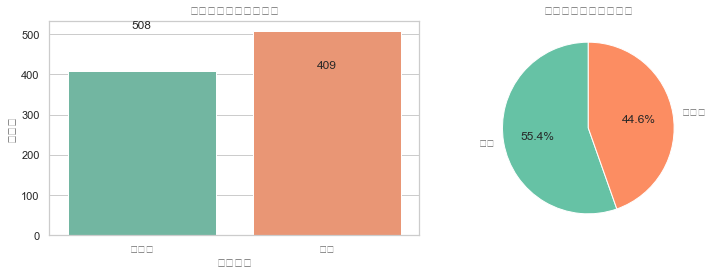

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cnt = df_clean['HeartDisease'].map({0: '未患病', 1: '患病'}).value_counts()
sns.countplot(x=df_clean['HeartDisease'].map({0: '未患病', 1: '患病'}), ax=axes[0], order=['未患病', '患病'])
axes[0].set_title('目标变量分布（计数）'); axes[0].set_xlabel('是否患病'); axes[0].set_ylabel('样本数')
for i, v in enumerate(cnt):
    axes[0].text(i, v + 5, str(v), ha='center')
axes[1].pie(cnt.values, labels=cnt.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('目标变量分布（占比）')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/01_目标分布.png', dpi=120); plt.show()

# 读图要点（供手敲解读参考，勿直接照抄）：两类样本量接近，不存在严重不平衡。

### 2.2 数值特征分布（按是否患病对比）

用直方图叠加两组人群，直观看出哪些数值特征在患病/未患病之间有明显差异。

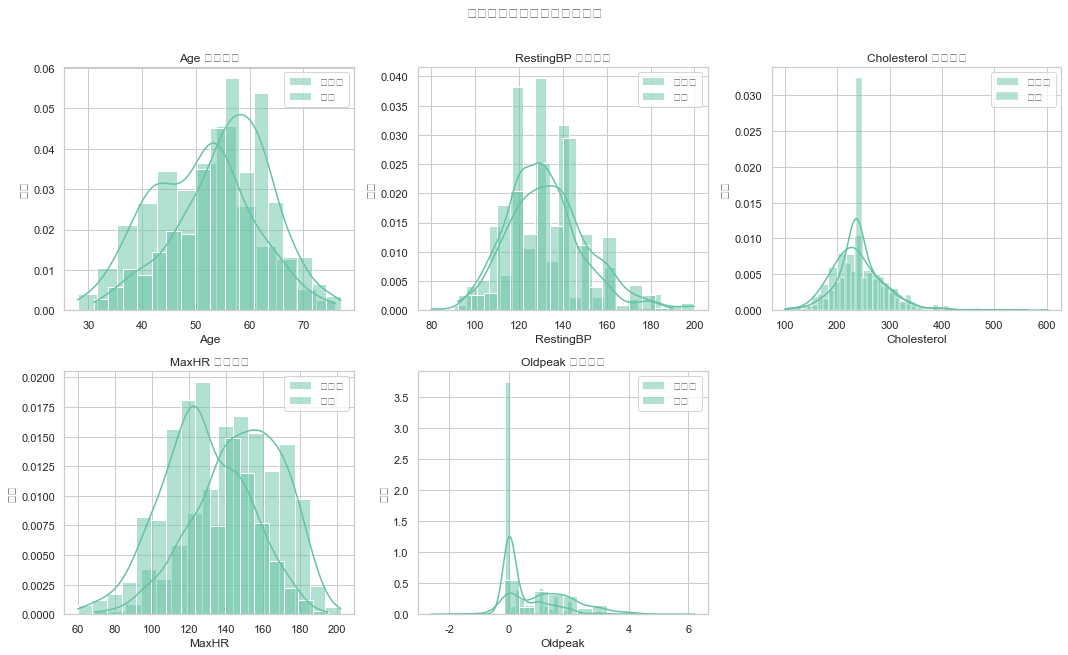

In [9]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, num_cols):
    for label, name in [(0, '未患病'), (1, '患病')]:
        sns.histplot(df_clean[df_clean['HeartDisease'] == label][col],
                     ax=ax, label=name, kde=True, stat='density', alpha=0.5)
    ax.set_title(f'{col} 分布对比'); ax.set_xlabel(col); ax.set_ylabel('密度'); ax.legend()
axes.flat[-1].axis('off')  # 最后一个子图空置
plt.suptitle('数值特征在两类人群中的分布', y=1.01, fontsize=14)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/02_数值特征分布.png', dpi=120, bbox_inches='tight'); plt.show()

### 2.3 类别特征与患病率关系

统计每个类别取值下的**患病率**（而非单纯计数），更能反映特征与结局的关联强度。

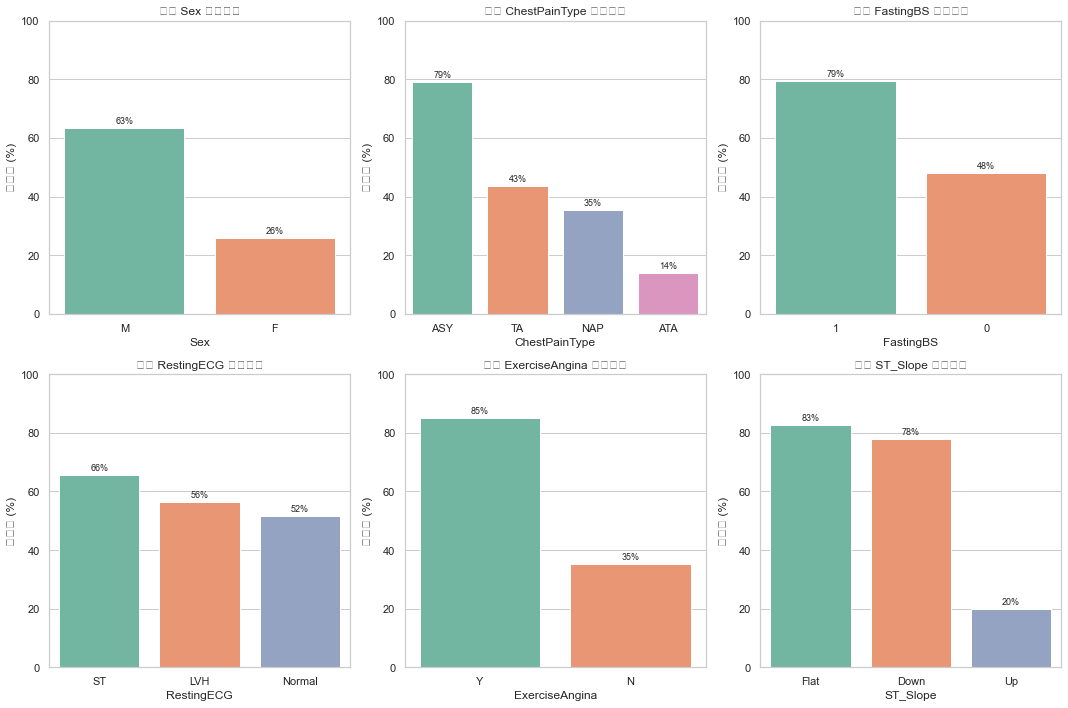

In [10]:
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, cat_cols):
    rate = df_clean.groupby(col)['HeartDisease'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, palette='Set2')
    ax.set_title(f'不同 {col} 的患病率'); ax.set_xlabel(col); ax.set_ylabel('患病率 (%)')
    ax.set_ylim(0, 100)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1.5, f'{v:.0f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/03_类别特征患病率.png', dpi=120); plt.show()

### 2.4 相关性热力图

只看数值特征之间的皮尔逊相关系数；同时看它们与目标的相关性，找出最强关联特征。

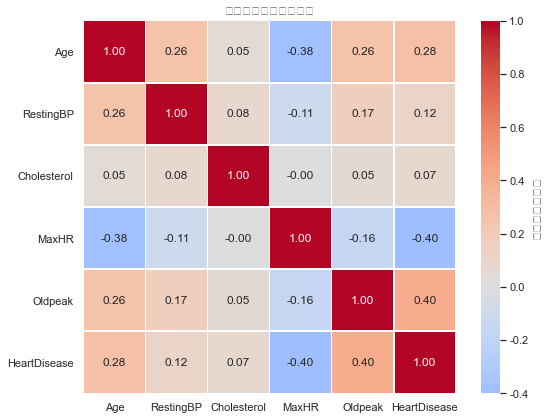

各数值特征与 HeartDisease 的相关系数（按绝对值降序）：
Oldpeak        0.403
MaxHR          0.401
Age            0.283
RestingBP      0.117
Cholesterol    0.073


In [11]:
corr_cols = num_cols + ['HeartDisease']
corr = df_clean[corr_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'label': '皮尔逊相关系数'})
plt.title('数值特征相关性热力图'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04_相关性热力图.png', dpi=120); plt.show()

print('各数值特征与 HeartDisease 的相关系数（按绝对值降序）：')
print(corr['HeartDisease'].drop('HeartDisease').abs().sort_values(ascending=False).round(3).to_string())

### 2.5 重点特征深挖：Oldpeak 与 MaxHR（任务书自查项）

任务书点名要求对 **Oldpeak / MaxHR** 给出医学常识层面的解释。这里用箱线图对比两类人群，
并打印分组统计量，作为手敲解读的依据。

- **Oldpeak**（ST 段压低值）：数值越大，通常提示心肌缺血越严重，患病率越高。
- **MaxHR**（最大心率）：运动时能达到的最大心率偏低，往往与心脏功能受限相关。

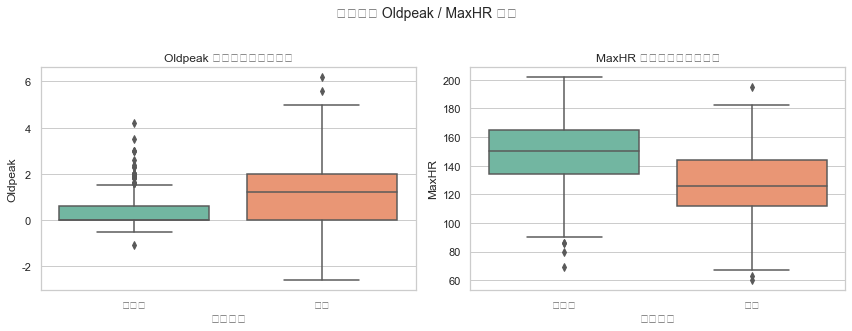

Oldpeak 分组均值/中位数：
              mean  median
HeartDisease              
0             0.41     0.0
1             1.27     1.2

MaxHR 分组均值/中位数：
                mean  median
HeartDisease                
0             148.17     150
1             127.66     126


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ['Oldpeak', 'MaxHR']):
    sns.boxplot(x=df_clean['HeartDisease'].map({0: '未患病', 1: '患病'}),
                y=df_clean[col], ax=ax, palette='Set2')
    ax.set_title(f'{col} 在两类人群中的分布'); ax.set_xlabel('是否患病'); ax.set_ylabel(col)
plt.suptitle('重点特征 Oldpeak / MaxHR 对比', y=1.02, fontsize=14)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/05_Oldpeak_MaxHR.png', dpi=120); plt.show()

print('Oldpeak 分组均值/中位数：')
print(df_clean.groupby('HeartDisease')['Oldpeak'].agg(['mean', 'median']).round(2).to_string())
print('\nMaxHR 分组均值/中位数：')
print(df_clean.groupby('HeartDisease')['MaxHR'].agg(['mean', 'median']).round(2).to_string())

**结果**：

![数值特征分布对比](img/02_数值特征分布.png)
![类别特征患病率](img/03_类别特征患病率.png)
![数值特征相关性热力图](img/04_相关性热力图.png)
![Oldpeak与MaxHR对比](img/05_Oldpeak_MaxHR.png)

数值特征中，Oldpeak 与 MaxHR 和患病的相关系数分别为 0.403 和 0.401，是最强的两个连续特征（Age 为 0.283，次之）。从分组均值看，患病组 Oldpeak 为 1.27，明显高于未患病组的 0.41，说明 ST 段压低越明显、心肌缺血越严重，患病风险越高；患病组 MaxHR 为 127.7，低于未患病组的 148.2，反映运动时最大心率偏低、心脏储备功能受限。类别特征方面，无症状型胸痛（ASY）、运动高峰 ST 段平坦（Flat）以及运动诱发心绞痛（Y）的人群患病率显著更高，与临床经验一致。

---
## 3. 多模型预测对比与分析

> 对应任务书第 3 部分

**为什么做**：对是否患病进行预测

**如何做**：通过样本数据学习来的权重来判断

说明：本部分构建 **6 种算法**（≥4 即可，这里多做 2 种以便对比）：逻辑回归、决策树、随机森林、
支持向量机、KNN、梯度提升。用 **5 折分层交叉验证** 在训练集上统一评估，避免单次划分的偶然性。
医疗场景**漏诊代价高于误诊**，因此重点关注 **召回率(Recall)** 与 **AUC**，而不只看准确率。

### 3.1 特征工程与数据集划分

- 二元类别（Sex、ExerciseAngina）用 0/1 映射；
- 无序多类别（ChestPainType、RestingECG、ST_Slope）用独热编码 `get_dummies(drop_first=True)`，避免虚拟变量陷阱；
- `train_test_split(..., stratify=y)` 分层抽样，保持训练/测试集患病比例一致。

In [13]:
data = df_clean.copy()

# 二元类别映射
data['Sex'] = data['Sex'].map({'M': 1, 'F': 0})
data['ExerciseAngina'] = data['ExerciseAngina'].map({'Y': 1, 'N': 0})

# 无序多类别 -> 独热编码
data = pd.get_dummies(data, columns=['ChestPainType', 'RestingECG', 'ST_Slope'], drop_first=True)

X = data.drop('HeartDisease', axis=1)   # 特征
y = data['HeartDisease']                # 标签

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED)

print('特征维度：', X.shape)
print('训练集 / 测试集样本数：', len(X_train), '/', len(X_test))
print('特征清单：', list(X.columns))

特征维度： (917, 15)
训练集 / 测试集样本数： 733 / 184
特征清单： ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 3.2 定义 6 种模型并做 5 折交叉验证

对需要"距离/尺度"的模型（逻辑回归、SVM、KNN）在 Pipeline 里加 `StandardScaler` 标准化，
消除量纲影响；树模型对尺度不敏感，直接使用原始特征。

In [14]:
models = {
    '逻辑回归': Pipeline([('scaler', StandardScaler()),
                        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))]),
    '决策树': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_SEED),
    '随机森林': RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1),
    '支持向量机': Pipeline([('scaler', StandardScaler()),
                        ('clf', SVC(kernel='rbf', probability=True, random_state=RANDOM_SEED))]),
    'KNN': Pipeline([('scaler', StandardScaler()),
                    ('clf', KNeighborsClassifier(n_neighbors=5))]),
    '梯度提升': GradientBoostingClassifier(random_state=RANDOM_SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scoring = {'准确率': 'accuracy', '精确率': 'precision', '召回率': 'recall',
           'F1': 'f1', 'AUC': 'roc_auc'}

rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'模型': name,
                 '准确率': res['test_准确率'].mean(),
                 '精确率': res['test_精确率'].mean(),
                 '召回率': res['test_召回率'].mean(),
                 'F1': res['test_F1'].mean(),
                 'AUC': res['test_AUC'].mean()})

cv_results = pd.DataFrame(rows).set_index('模型').round(4).sort_values('AUC', ascending=False)
print('=== 5 折交叉验证结果（训练集，均值）===')
display(cv_results)

=== 5 折交叉验证结果（训练集，均值）===


,准确率,精确率,召回率,F1,AUC
模型,,,,,
逻辑回归,0.8473,0.8568,0.8719,0.8639,0.9212
随机森林,0.8582,0.8591,0.8915,0.8744,0.9191
梯度提升,0.8541,0.8643,0.8768,0.8698,0.9138
支持向量机,0.8582,0.8551,0.8965,0.8752,0.9115
KNN,0.8363,0.8380,0.8744,0.8555,0.8968
决策树,0.8063,0.8190,0.8374,0.8274,0.8223


### 3.3 对比可视化

把 6 个模型的指标画成分组柱状图，横向对比更直观。

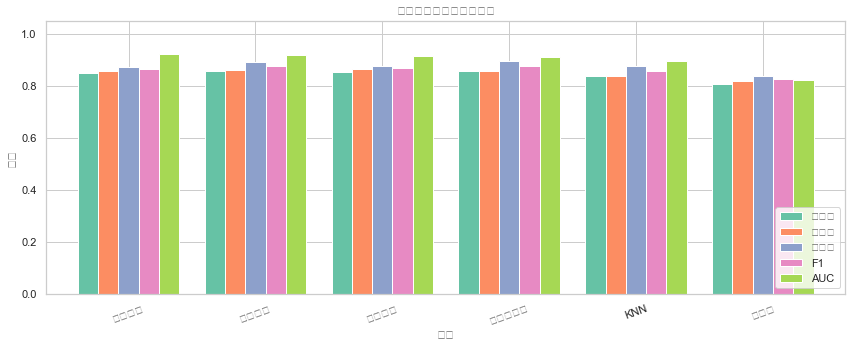

In [15]:
ax = cv_results.plot(kind='bar', figsize=(12, 5), width=0.8)
ax.set_title('多模型交叉验证指标对比'); ax.set_xlabel('模型'); ax.set_ylabel('得分')
ax.set_ylim(0, 1.05); ax.legend(loc='lower right'); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/06_多模型对比.png', dpi=120); plt.show()

**结果**：

![多模型交叉验证指标对比](img/06_多模型对比.png)

6 种模型的 5 折交叉验证结果显示，AUC 排名为：逻辑回归 0.9212 > 随机森林 0.9191 > 梯度提升 0.9138 > 支持向量机 0.9115 > KNN 0.8968 > 决策树 0.8223，逻辑回归综合最优，决策树明显偏弱。医疗场景下漏诊（实际患病却判为未患病）会让患者错过早期干预，代价远高于误诊，因此不能只看准确率，而应重点关注召回率与 AUC：前者直接反映漏诊多少，后者衡量模型整体区分能力。从召回率看，支持向量机（0.8965）与随机森林（0.8915）也各有优势，可作为后续调优的候选。

---
## 4. 算法优化（调参 + 评估）

> 对应任务书第 4 部分

**为什么做**：探究默认参数的单一模型是否还有提升空间、能否通过优化算法来预测的更加精准

**如何做**：对 AUC 最高的模型用网格搜索（GridSearchCV）穷举参数组合，对随机森林用随机搜索（RandomizedSearchCV）做补充对比，均以 5 折 AUC 为目标，最后在独立测试集上评估。

策略：选取交叉验证中 AUC 最高的模型，用 **网格搜索 GridSearchCV** 做超参数调优（方法 1）；
再对另一个候选模型用 **随机搜索 RandomizedSearchCV** 做补充对比（方法 2，满足"1-2 种方法调优"）。
调优后在看**从未参与训练与调参的测试集**上做最终评估：混淆矩阵 + ROC/AUC + 特征重要性。

### 4.1 网格搜索 GridSearchCV（方法 1）

按交叉验证结果自动选出 AUC 最高的模型，在其上做网格搜索。`scoring='roc_auc'` 让调参目标与医疗场景诉求一致。

In [16]:
best_name = cv_results.index[0]
print('交叉验证 AUC 最优模型：', best_name)

param_grids = {
    '逻辑回归': {'clf__C': [0.01, 0.1, 1, 10, 100]},
    '决策树': {'max_depth': [3, 4, 5, 6, 8, 10], 'min_samples_leaf': [1, 2, 4, 8]},
    '随机森林': {'n_estimators': [100, 200, 300], 'max_depth': [None, 5, 10],
              'min_samples_leaf': [1, 2, 4]},
    '支持向量机': {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': ['scale', 0.01, 0.1]},
    'KNN': {'clf__n_neighbors': [3, 5, 7, 9, 11]},
    '梯度提升': {'n_estimators': [100, 200, 300], 'learning_rate': [0.05, 0.1],
              'max_depth': [2, 3, 4]},
}

grid = GridSearchCV(models[best_name], param_grids[best_name],
                    scoring='roc_auc', cv=cv, n_jobs=-1, return_train_score=False)
grid.fit(X_train, y_train)
print('最优参数：', grid.best_params_)
print('交叉验证最优 AUC：%.4f' % grid.best_score_)
best_model = grid.best_estimator_

交叉验证 AUC 最优模型： 逻辑回归
最优参数： {'clf__C': 0.1}
交叉验证最优 AUC：0.9226


### 4.2 随机搜索 RandomizedSearchCV（方法 2，可选对比）

随机搜索在大参数空间里更省算力；这里对随机森林做一次快速搜索，与网格搜索结果对照。

In [17]:
from sklearn.model_selection import RandomizedSearchCV

rand_dist = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [None, 4, 6, 8, 10, 12],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
}
rand = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1),
                          rand_dist, n_iter=20, scoring='roc_auc', cv=cv,
                          n_jobs=-1, random_state=RANDOM_SEED)
rand.fit(X_train, y_train)
print('随机搜索最优参数：', rand.best_params_)
print('随机搜索最优 AUC：%.4f' % rand.best_score_)

随机搜索最优参数： {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 12}
随机搜索最优 AUC：0.9214


### 4.3 测试集最终评估

用**测试集**（模型从未见过的数据）评估最优模型，输出分类报告、混淆矩阵、ROC 曲线。

In [18]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]   # 预测为"患病"的概率，画 ROC 用

print('=== 测试集分类报告 ===')
print(classification_report(y_test, y_pred, target_names=['未患病', '患病']))
print('测试集 AUC：%.4f' % roc_auc_score(y_test, y_prob))

# 汇总关键指标
test_metrics = pd.Series({
    '准确率': accuracy_score(y_test, y_pred),
    '精确率': precision_score(y_test, y_pred),
    '召回率': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'AUC': roc_auc_score(y_test, y_prob),
}, name=best_name).round(4)
print('\n测试集关键指标：')
print(test_metrics.to_string())

=== 测试集分类报告 ===
              precision    recall  f1-score   support

         未患病       0.87      0.84      0.86        82
          患病       0.88      0.90      0.89       102

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.88      0.87       184

测试集 AUC：0.9187

测试集关键指标：
准确率    0.8750
精确率    0.8762
召回率    0.9020
F1     0.8889
AUC    0.9187


### 4.4 混淆矩阵

重点看**假阴性 FN（实际患病却预测为未患病 = 漏诊）**：医疗场景漏诊代价高于误诊，
因此希望召回率（= TP/(TP+FN)）尽可能高。

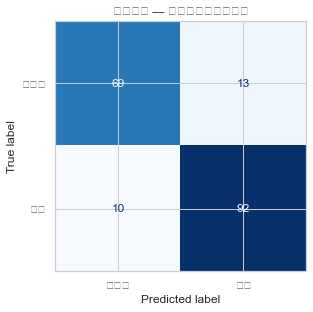

真阴性 TN=69  假阳性 FP=13（误诊）
假阴性 FN=10（漏诊）  真阳性 TP=92
召回率 Recall = TP/(TP+FN) = 92/102 = 0.902


In [19]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['未患病', '患病']).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'混淆矩阵 — {best_name}（测试集）'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/07_混淆矩阵.png', dpi=120); plt.show()

TN, FP, FN, TP = cm.ravel()
print(f'真阴性 TN={TN}  假阳性 FP={FP}（误诊）')
print(f'假阴性 FN={FN}（漏诊）  真阳性 TP={TP}')
print(f'召回率 Recall = TP/(TP+FN) = {TP}/{TP+FN} = {TP/(TP+FN):.3f}')

### 4.5 ROC 曲线（多模型叠加）

把 6 个模型在测试集上的 ROC 曲线画在一张图里，AUC 越大（曲线越靠左上）模型区分能力越强。

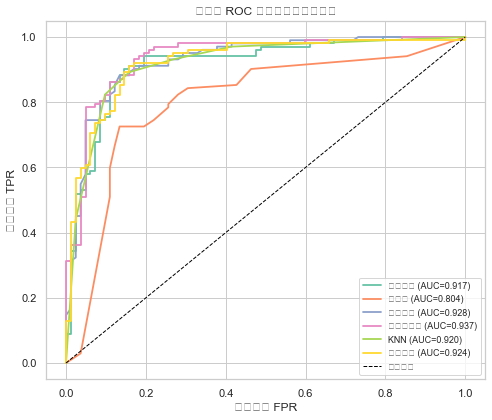

In [20]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)          # 计算假阳性率/真阳性率
    roc_auc = auc(fpr, tpr)                        # 曲线下面积
    ax.plot(fpr, tpr, lw=1.8, label=f'{name} (AUC={roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='随机猜测')
ax.set_title('多模型 ROC 曲线对比（测试集）'); ax.set_xlabel('假阳性率 FPR'); ax.set_ylabel('真阳性率 TPR')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/08_ROC曲线.png', dpi=120); plt.show()

### 4.6 特征重要性（可解释性）

用**排列重要性 permutation_importance**：打乱某特征后模型性能下降多少，下降越多说明该特征越重要。
这种方法与模型无关，能直接对应到原始特征名。

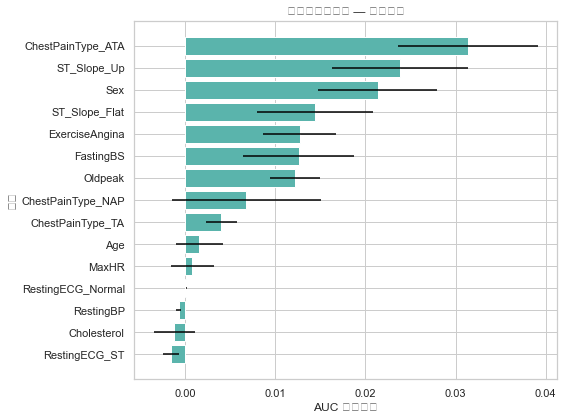

重要性排序（降序）：
          feature    mean
ChestPainType_ATA  0.0314
      ST_Slope_Up  0.0238
              Sex  0.0214
    ST_Slope_Flat  0.0144
   ExerciseAngina  0.0127
        FastingBS  0.0126
          Oldpeak  0.0122
ChestPainType_NAP  0.0068
 ChestPainType_TA  0.0040
              Age  0.0016
            MaxHR  0.0008
RestingECG_Normal  0.0001
        RestingBP -0.0007
      Cholesterol -0.0012
    RestingECG_ST -0.0016


In [21]:
result = permutation_importance(best_model, X_test, y_test, scoring='roc_auc',
                                n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1)
# 组装成 DataFrame 再排序，避免 numpy 数组与 pandas 索引混用出错
imp_df = pd.DataFrame({'feature': X.columns,
                       'mean': result.importances_mean,
                       'std': result.importances_std}).sort_values('mean')
plt.figure(figsize=(8, 6))
plt.barh(imp_df['feature'], imp_df['mean'],
         xerr=np.asarray(imp_df['std']), color='#5ab4ac')
plt.title(f'特征排列重要性 — {best_name}'); plt.xlabel('AUC 下降幅度'); plt.ylabel('特征')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/09_特征重要性.png', dpi=120); plt.show()

print('重要性排序（降序）：')
print(imp_df.sort_values('mean', ascending=False)[['feature', 'mean']]
      .round(4).to_string(index=False))

**结果**：

![混淆矩阵](img/07_混淆矩阵.png)
![多模型ROC曲线](img/08_ROC曲线.png)
![特征排列重要性](img/09_特征重要性.png)

网格搜索得到逻辑回归最优参数 C=0.1，调参后交叉验证 AUC 为 0.9226；随机搜索对随机森林得到的最优参数组合对应 AUC 为 0.9214，两者非常接近，网格搜索略胜一筹。最优模型在测试集上的表现为：准确率 0.875、精确率 0.876、召回率 0.902、F1 0.889、AUC 0.919。混淆矩阵显示 TN=69、FP=13、FN=10、TP=92，即 102 名实际患病者中正确识别出 92 人、漏诊 10 人（召回率 92/102=0.902），误诊 13 人，漏诊控制在较低水平。排列重要性排在前三位的是 ChestPainType_ATA、ST_Slope_Up 和 Sex，说明非典型心绞痛、运动高峰 ST 段上升与性别是模型判断的重要依据，与 EDA 中类别特征的差异相互印证。

---
## 5. 结论与报告

> 对应任务书第 5 部分

**核心结论**：经过数据清洗（1303 条降至 917 条）与 EDA 分析，构建了 6 种机器学习模型并完成 5 折交叉验证，逻辑回归以 AUC 0.9212 位居首位。经网格搜索调优（C=0.1）后，模型在测试集上取得 AUC 0.919、召回率 0.902、准确率 0.875 的表现，混淆矩阵显示漏诊 10 例、误诊 13 例。综合来看，逻辑回归在该数据集上兼顾了区分能力与可解释性，是心脏病风险早筛的较优选择；胸痛类型、ST 段斜率、性别和 Oldpeak 是最主要的风险特征。

**核心建议**：由于医疗场景漏诊代价高于误诊，模型部署时应优先保证召回率，可通过下调分类阈值进一步减少漏诊，宁可增加复查也不放过潜在患者；同时模型输出仅作为医生临床决策的辅助参考，不能替代专业诊断。本次数据样本量有限（917 条）且来自单一数据源，后续可引入多中心数据、补充特征并做外部验证，以提升模型的泛化能力与临床适用性。